Loading proteomics data and computing Kruskal-Wallis effect sizes...

Top 10 features by epsilon-squared:
  PDCD6IP      ε²=0.438 · FDR 1.2e-08
  KRT76        ε²=0.413 · FDR 1.9e-08
  CC2D2B       ε²=0.411 · FDR 1.9e-08
  SLC25A18     ε²=0.374 · FDR 1.3e-07
  PTGS1        ε²=0.365 · FDR 1.7e-07
  KRT23        ε²=0.355 · FDR 2.7e-07
  CEP120       ε²=0.339 · FDR 5.7e-07
  ANXA7        ε²=0.327 · FDR 9.9e-07
  PBXIP1       ε²=0.321 · FDR 1.2e-06
  VAPB         ε²=0.319 · FDR 1.3e-06


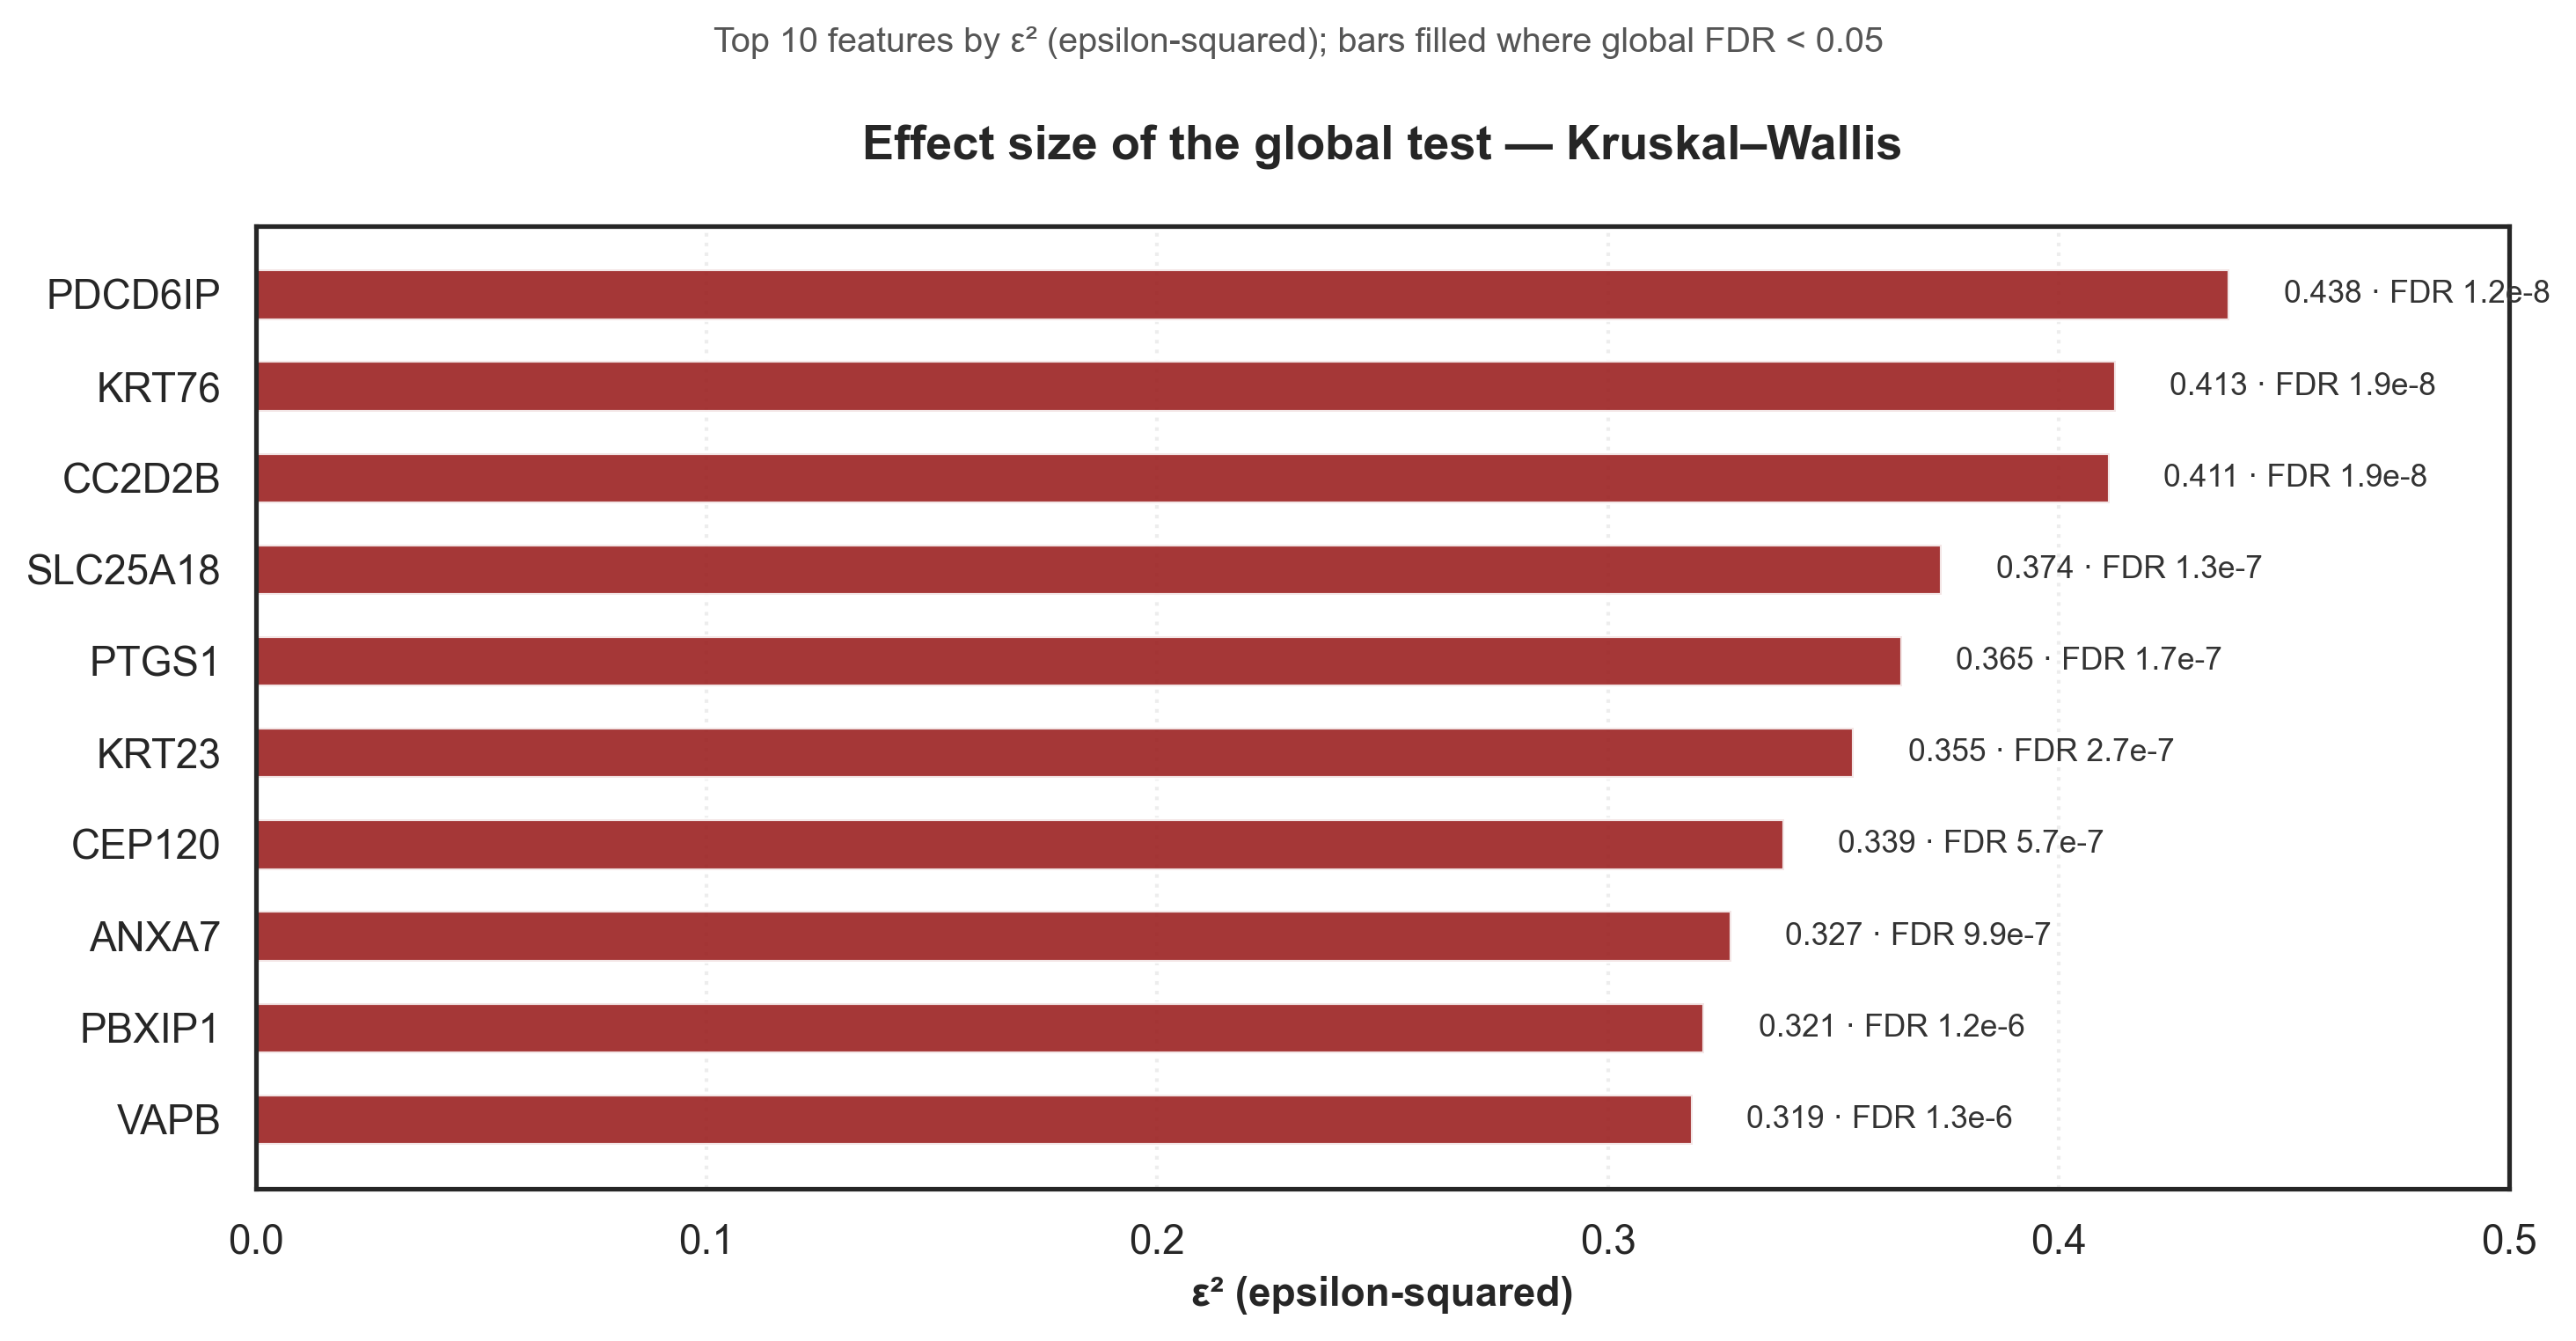


Saved Kruskal–Wallis plot to benchmarks\kruskal_wallis_effect_size_top10.png


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2

def kruskal_wallis_protbed(group_arrays):
    k = len(group_arrays)
    combined = []
    for gi, g in enumerate(group_arrays):
        for v in g:
            combined.append((v, gi))
    
    N = len(combined)
    if N <= k:
        return 0.0, 1.0, 0.0

    combined.sort(key=lambda x: x[0])
    ranks = np.zeros(N)
    i = 0
    while i < N:
        j = i
        while j < N - 1 and combined[j + 1][0] == combined[j][0]:
            j += 1
        avg_rank = (i + j) / 2.0 + 1.0
        for m in range(i, j + 1):
            ranks[m] = avg_rank
        i = j + 1

    rank_sums = [0.0] * k
    for m in range(N):
        rank_sums[combined[m][1]] += ranks[m]

    H = 0.0
    for gi, g in enumerate(group_arrays):
        if len(g) > 0:
            H += (rank_sums[gi] ** 2) / len(g)
    H = (12.0 / (N * (N + 1))) * H - 3.0 * (N + 1)

    if H <= 0 or np.isnan(H):
        return 0.0, 1.0, 0.0

    pval = chi2.sf(H, k - 1)

    denom = N - k
    eps = max(0.0, min(1.0, (H - k + 1) / denom)) if denom > 0 else 0.0

    return H, pval, eps


def fdr_bh(p_values):
    """Benjamini-Hochberg FDR correction."""
    p_vals = np.asarray(p_values)
    n = len(p_vals)
    order = np.argsort(p_vals)
    ranks = np.empty(n, int)
    ranks[order] = np.arange(1, n + 1)
    fdr = p_vals * n / ranks
    fdr_sorted = np.minimum.accumulate(fdr[order][::-1])[::-1]
    out = np.empty(n)
    out[order] = np.clip(fdr_sorted, 0, 1)
    return out


def generate_kruskal_effect_size_plot(file_path="data/pdac_ev_proteomics.xlsx", output_dir="benchmarks"):
    os.makedirs(output_dir, exist_ok=True)

    xls = pd.ExcelFile(file_path)
    df = pd.read_excel(file_path, sheet_name=xls.sheet_names[0])

    name_col = 'Gene Symbol' if 'Gene Symbol' in df.columns else df.columns[0]
    abundance_cols = [c for c in df.columns if 'Abundances (Normalized):' in c]

    sample_to_group = {}
    for col in abundance_cols:
        text = col.split(':', 1)[1]
        tokens = [t.strip().upper() for t in text.split(',')]
        group_found = 'Other'
        for token in tokens:
            if 'CONTROL' in token: group_found = 'Control'; break
            elif token == 'CP': group_found = 'CP'; break
            elif 'IPMN' in token: group_found = 'IPMN'; break
            elif token == 'PA': group_found = 'PA'; break
        sample_to_group[col] = group_found

    groups = ['Control', 'CP', 'IPMN', 'PA']
    group_cols = {g: [c for c in abundance_cols if sample_to_group[c] == g] for g in groups}

    df_filtered = df.copy()
    df_filtered['temp_mean_abundance'] = df_filtered[abundance_cols].mean(axis=1)
    df_filtered = df_filtered.sort_values(by='temp_mean_abundance', ascending=False)
    df_filtered = df_filtered.drop_duplicates(subset=[name_col], keep='first').copy()
    df_filtered = df_filtered.drop(columns=['temp_mean_abundance'])

    df_imputed = df_filtered[abundance_cols].fillna(0)

    log2_data = np.log2(df_imputed.replace(0, np.nan))
    min_val = log2_data.min().min() if not log2_data.min().empty else 0
    log2_data = log2_data.fillna(min_val).values
    
    gene_names = df_filtered[name_col].values

    H_stats, p_vals, eps_values = [], [], []
    for idx in range(len(df_filtered)):
        row_vals = log2_data[idx]
        g_arrays = [
            row_vals[[abundance_cols.index(c) for c in group_cols[g]]]
            for g in groups
        ]
        H, p, eps = kruskal_wallis_protbed(g_arrays)
        H_stats.append(H)
        p_vals.append(p)
        eps_values.append(eps)

    fdr_vals = fdr_bh(p_vals)

    res_df = pd.DataFrame({
        'Gene Symbol': gene_names,
        'H_stat': H_stats,
        'P-value': p_vals,
        'FDR': fdr_vals,
        'epsilon_squared': eps_values
    }).sort_values('epsilon_squared', ascending=False).reset_index(drop=True)

    top10 = res_df.head(10).copy()

    print("\nTop 10 features by epsilon-squared:")
    for _, r in top10.iterrows():
        print(f"  {r['Gene Symbol']:<12} \u03b5\u00b2={r['epsilon_squared']:.3f} · FDR {r['FDR']:.1e}")

    plt.figure(figsize=(10, 5.5), dpi=300)
    sns.set_theme(style="white")

    bar_color = '#991b1b'
    bars = plt.barh(
        top10['Gene Symbol'][::-1],
        top10['epsilon_squared'][::-1],
        color=bar_color,
        alpha=0.88,
        height=0.55
    )

    plt.title("Effect size of the global test \u2014 Kruskal\u2013Wallis", fontsize=13, fontweight='bold', pad=18)
    plt.suptitle("Top 10 features by \u03b5\u00b2 (epsilon-squared); bars filled where global FDR < 0.05", fontsize=9.5, y=0.92, color='#555555')
    plt.xlabel("\u03b5\u00b2 (epsilon-squared)", fontsize=11, fontweight='bold')
    plt.xlim(0, 0.50)
    plt.grid(axis='x', linestyle=':', alpha=0.5, color='#dddddd')

    for bar, (_, row) in zip(bars, top10.iloc[::-1].iterrows()):
        width = bar.get_width()
        fdr_val = row['FDR']
        fdr_str = f"{fdr_val:.1e}".replace('e-0', 'e-')
        val_text = f"{width:.3f} \u00b7 FDR {fdr_str}"
        plt.text(width + 0.012, bar.get_y() + bar.get_height() / 2, val_text,
                 va='center', ha='left', fontsize=8.5, color='#333333')

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    output_path = os.path.join(output_dir, "kruskal_wallis_effect_size_top10.png")
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"\nSaved Kruskal\u2013Wallis plot to {output_path}")

if __name__ == "__main__":
    generate_kruskal_effect_size_plot("data/pdac_ev_proteomics.xlsx")

Loading proteomics data...


C:\Users\Anas\AppData\Local\Temp\ipykernel_6528\2909147846.py:51: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['temp_mean_abundance'] = df[abundance_cols].mean(axis=1)


Generating Z-score distribution boxplot...


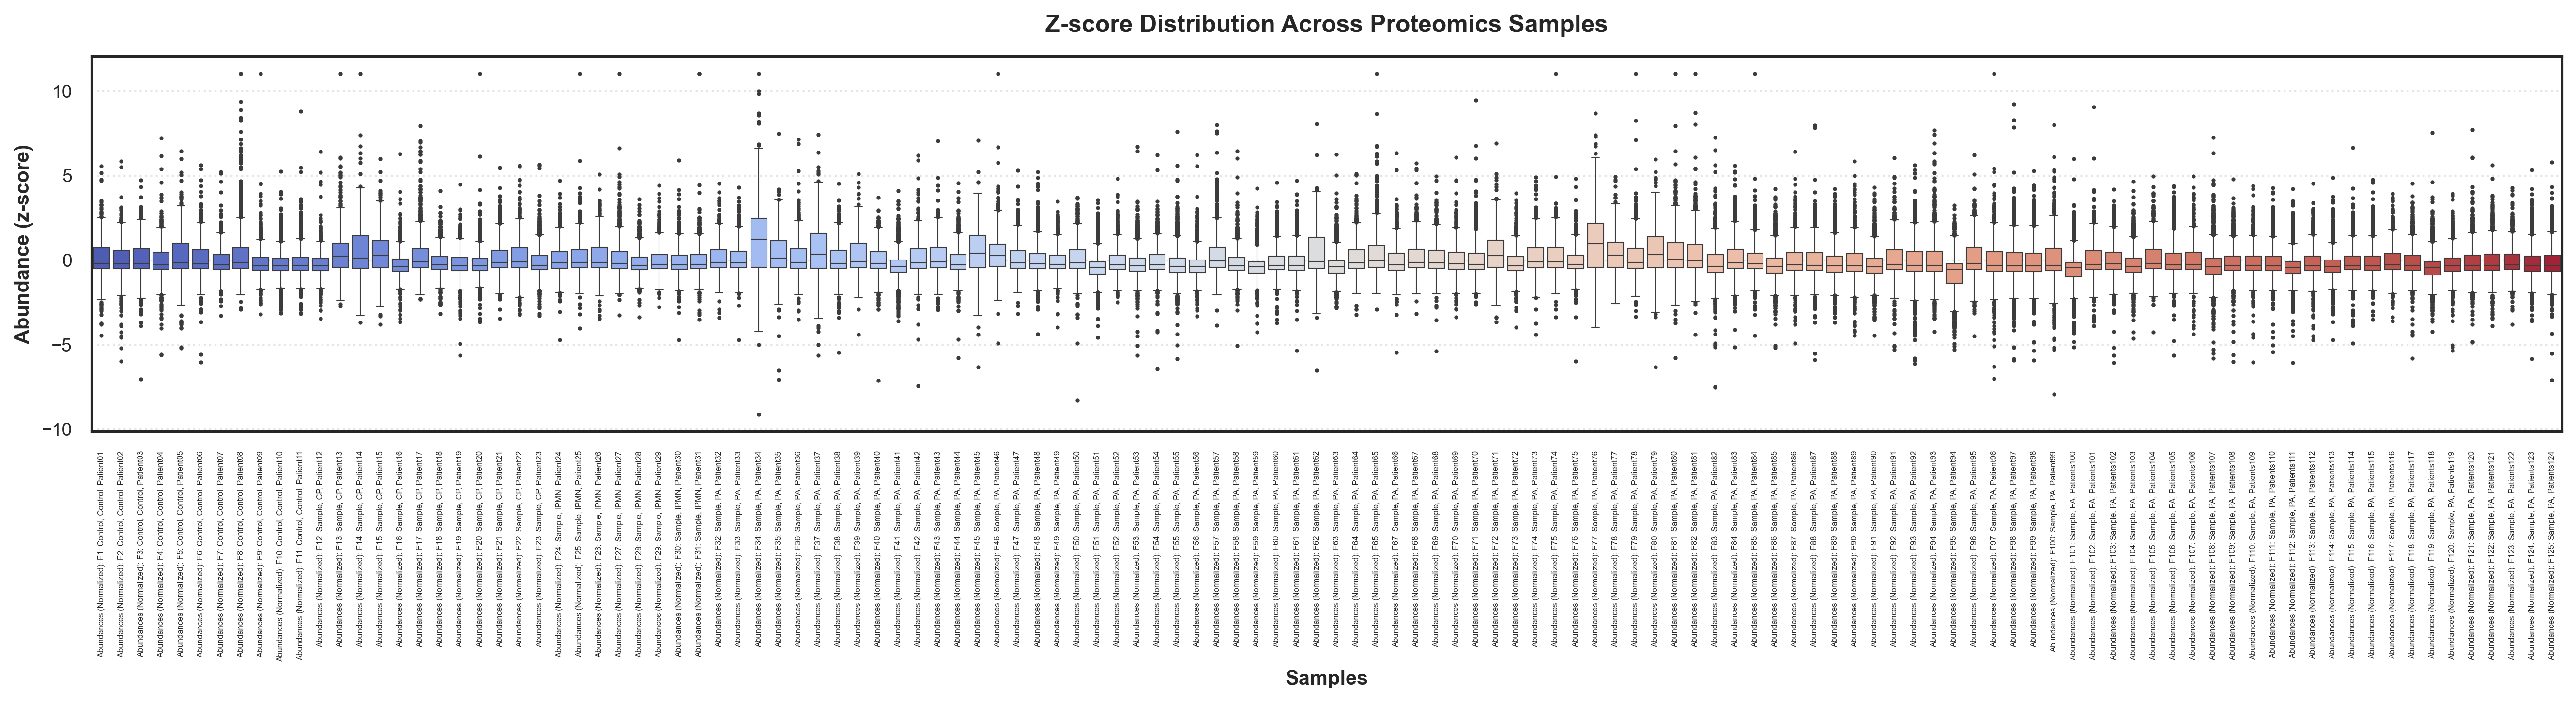

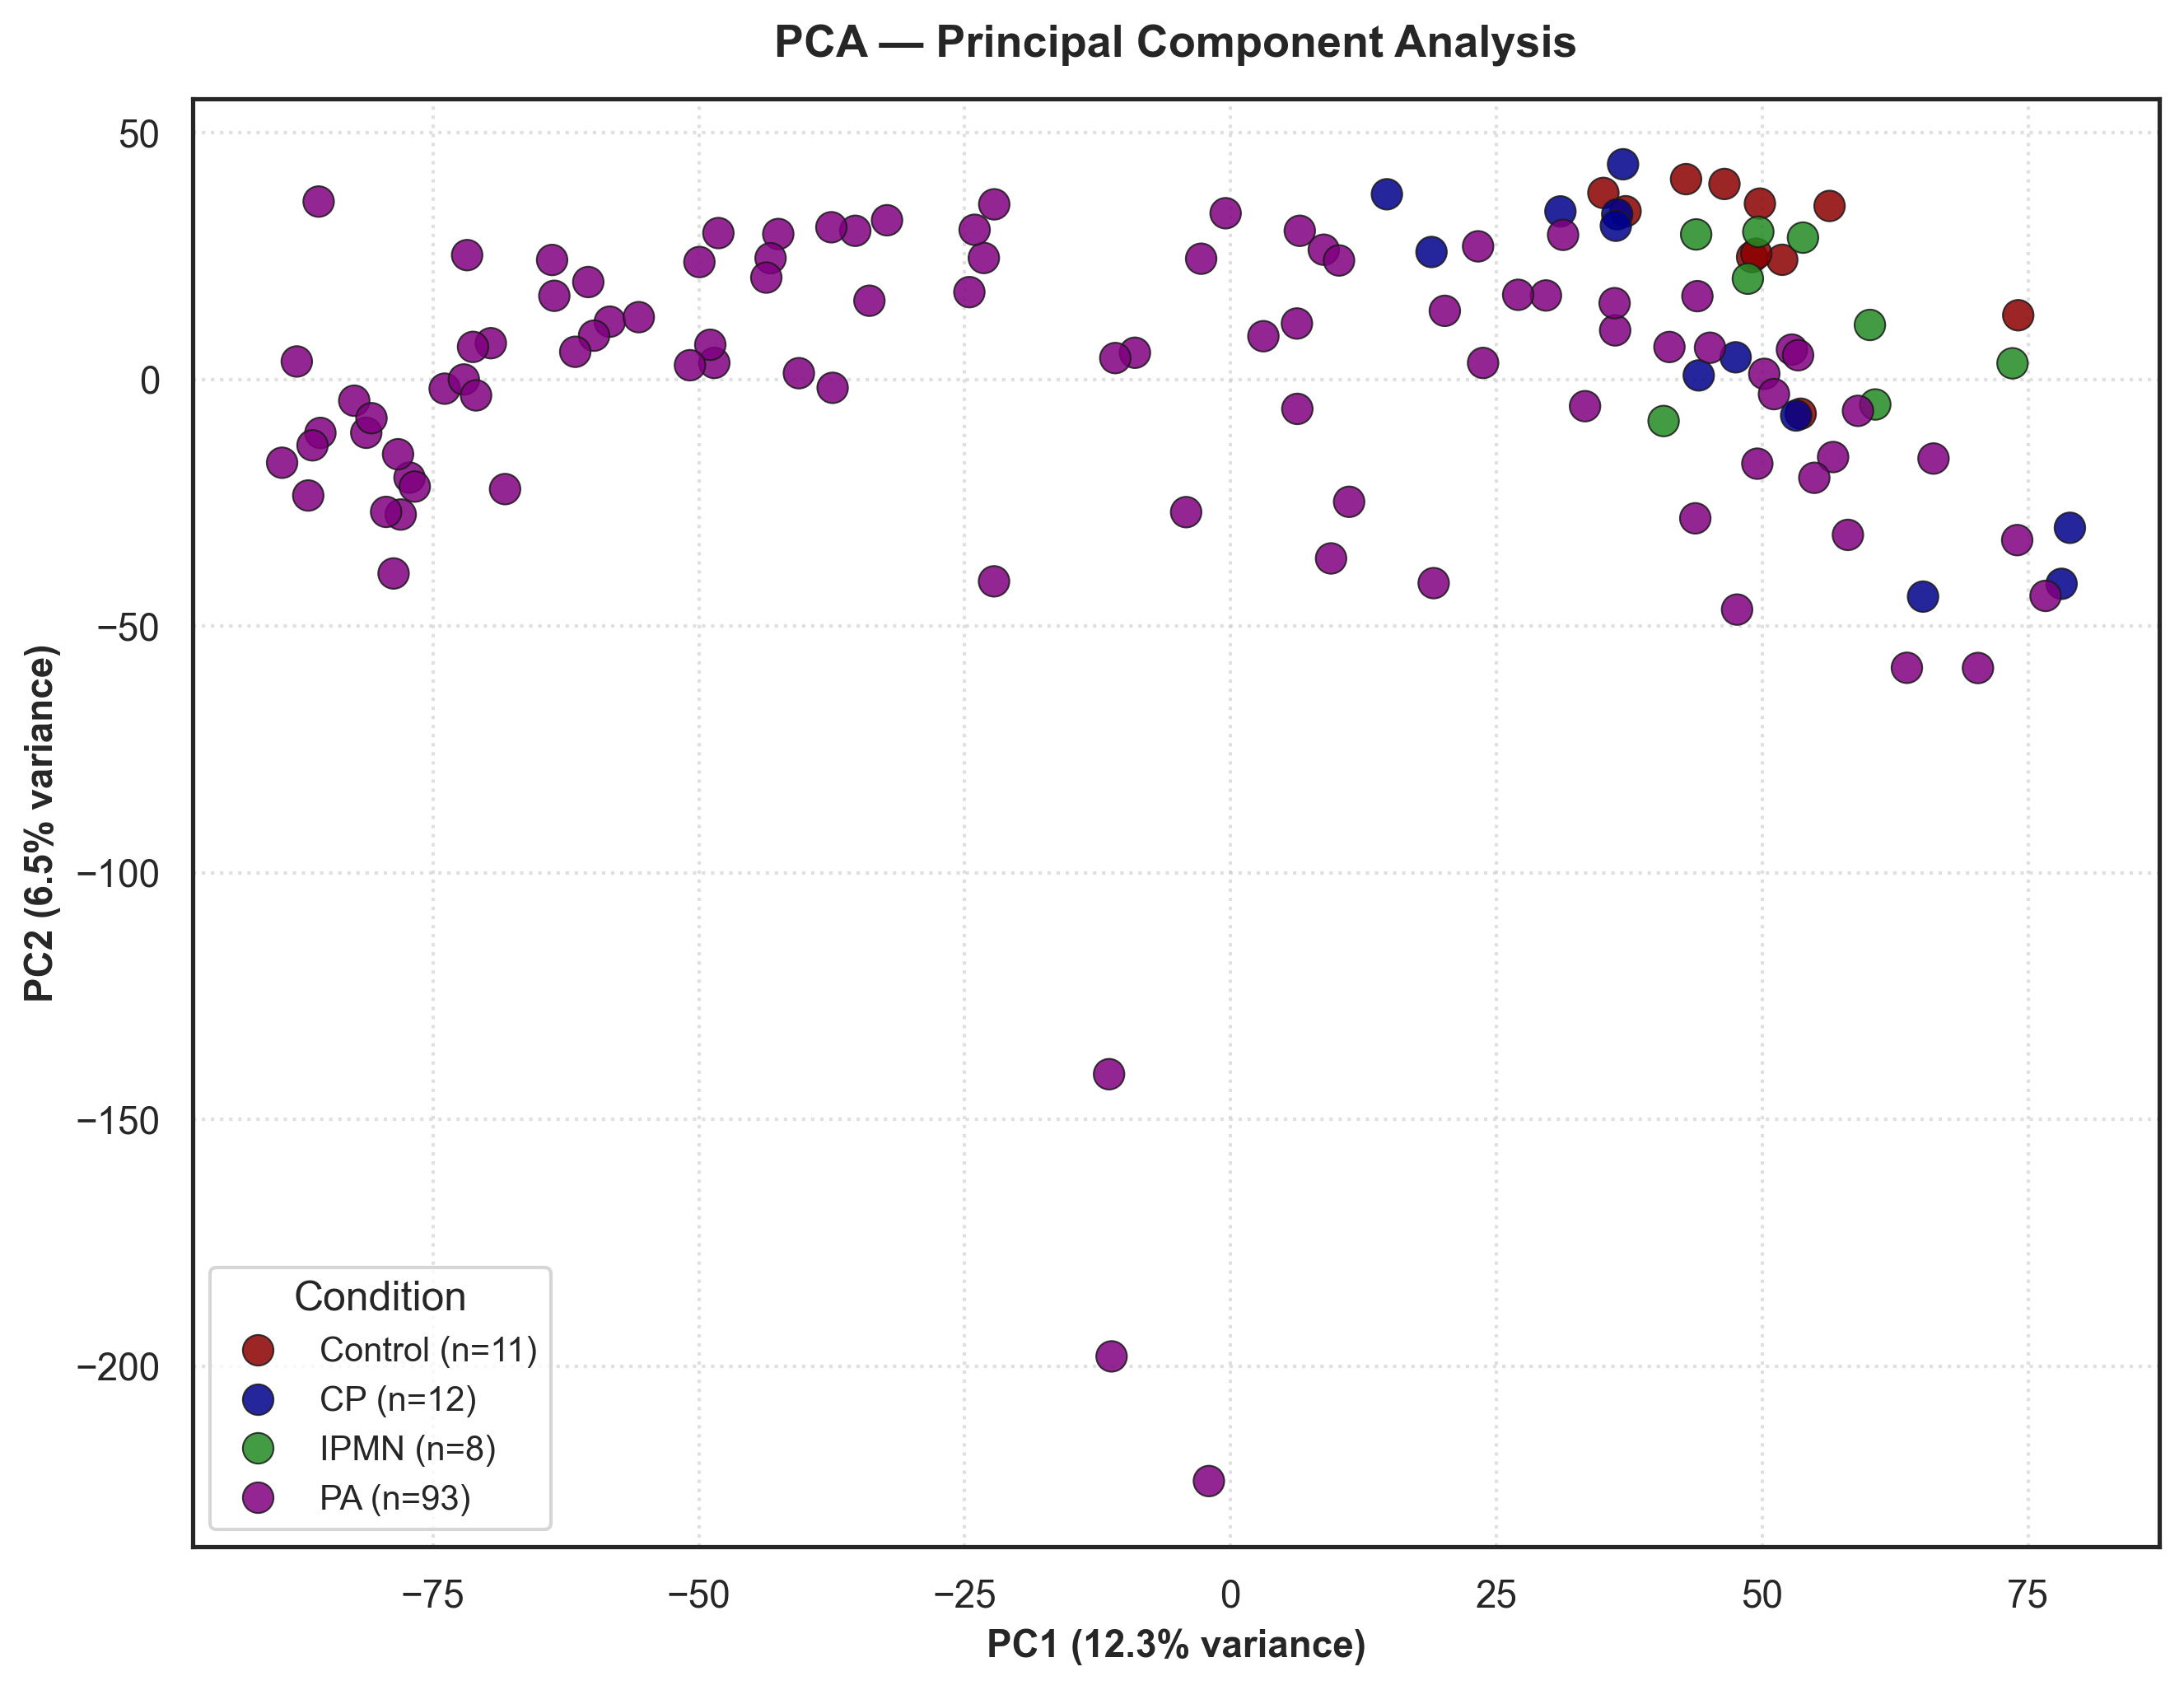

Running Sample-level UMAP...


C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


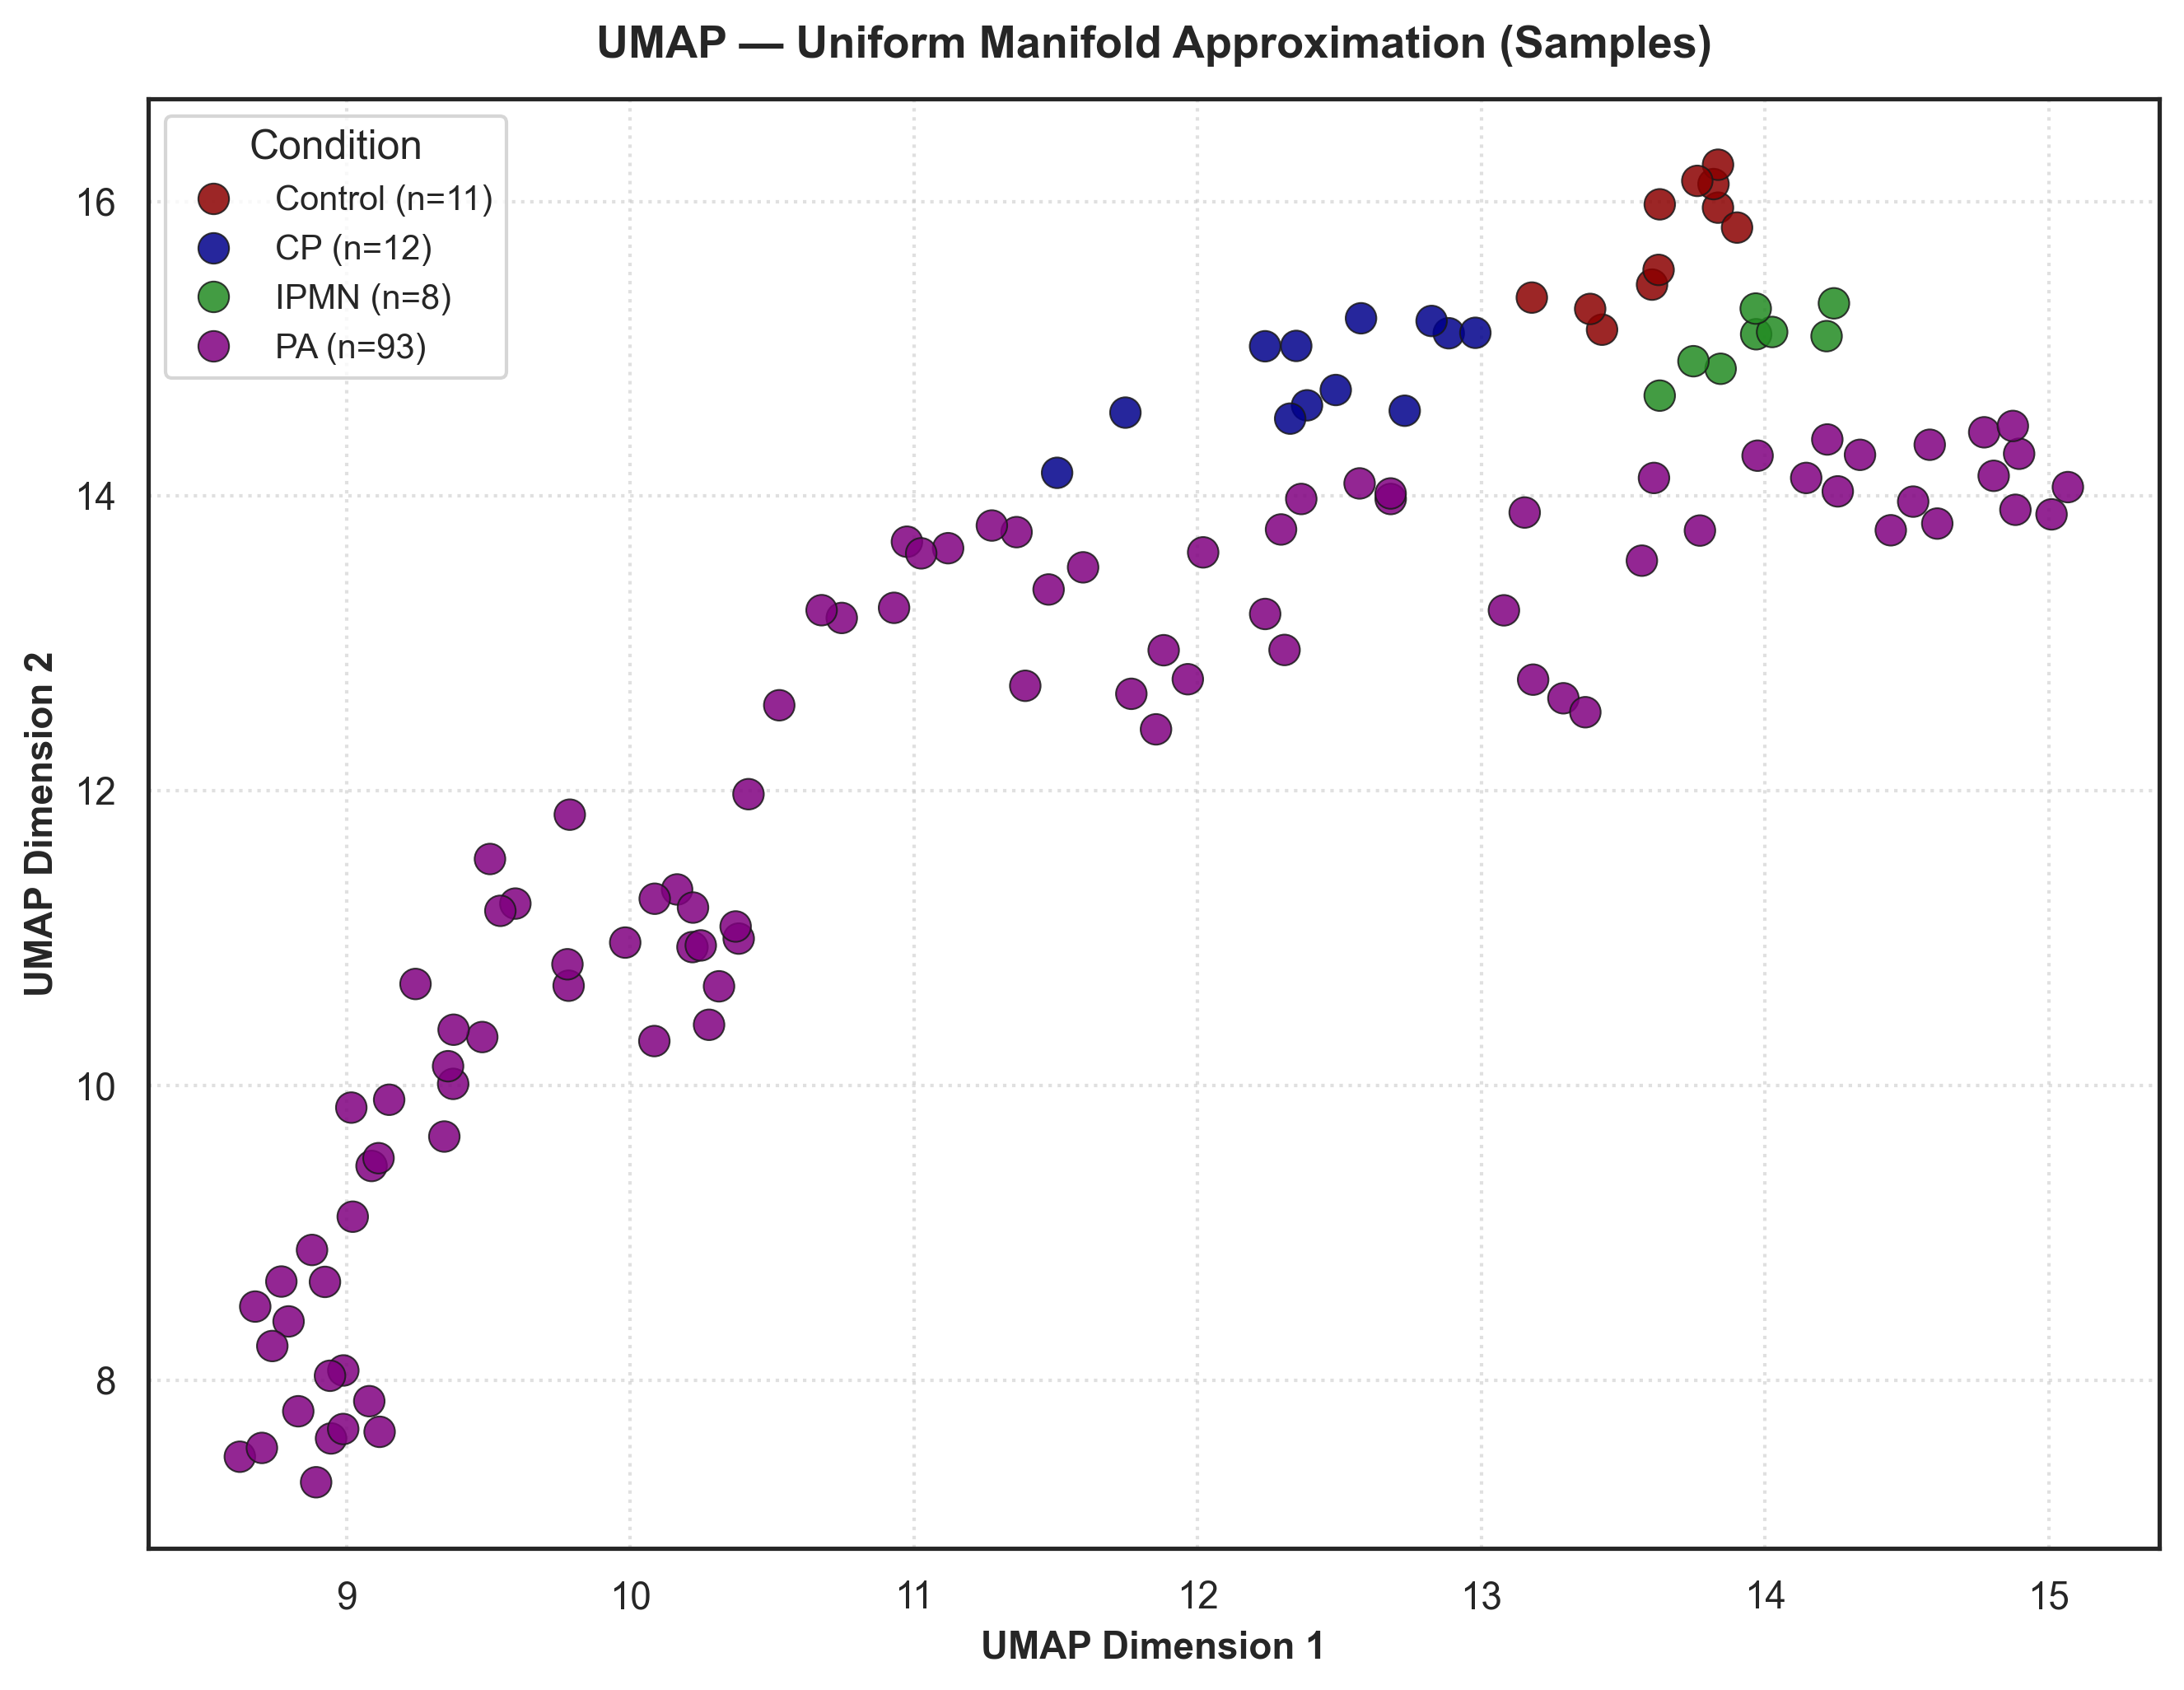

Running Protein-level UMAP...


C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


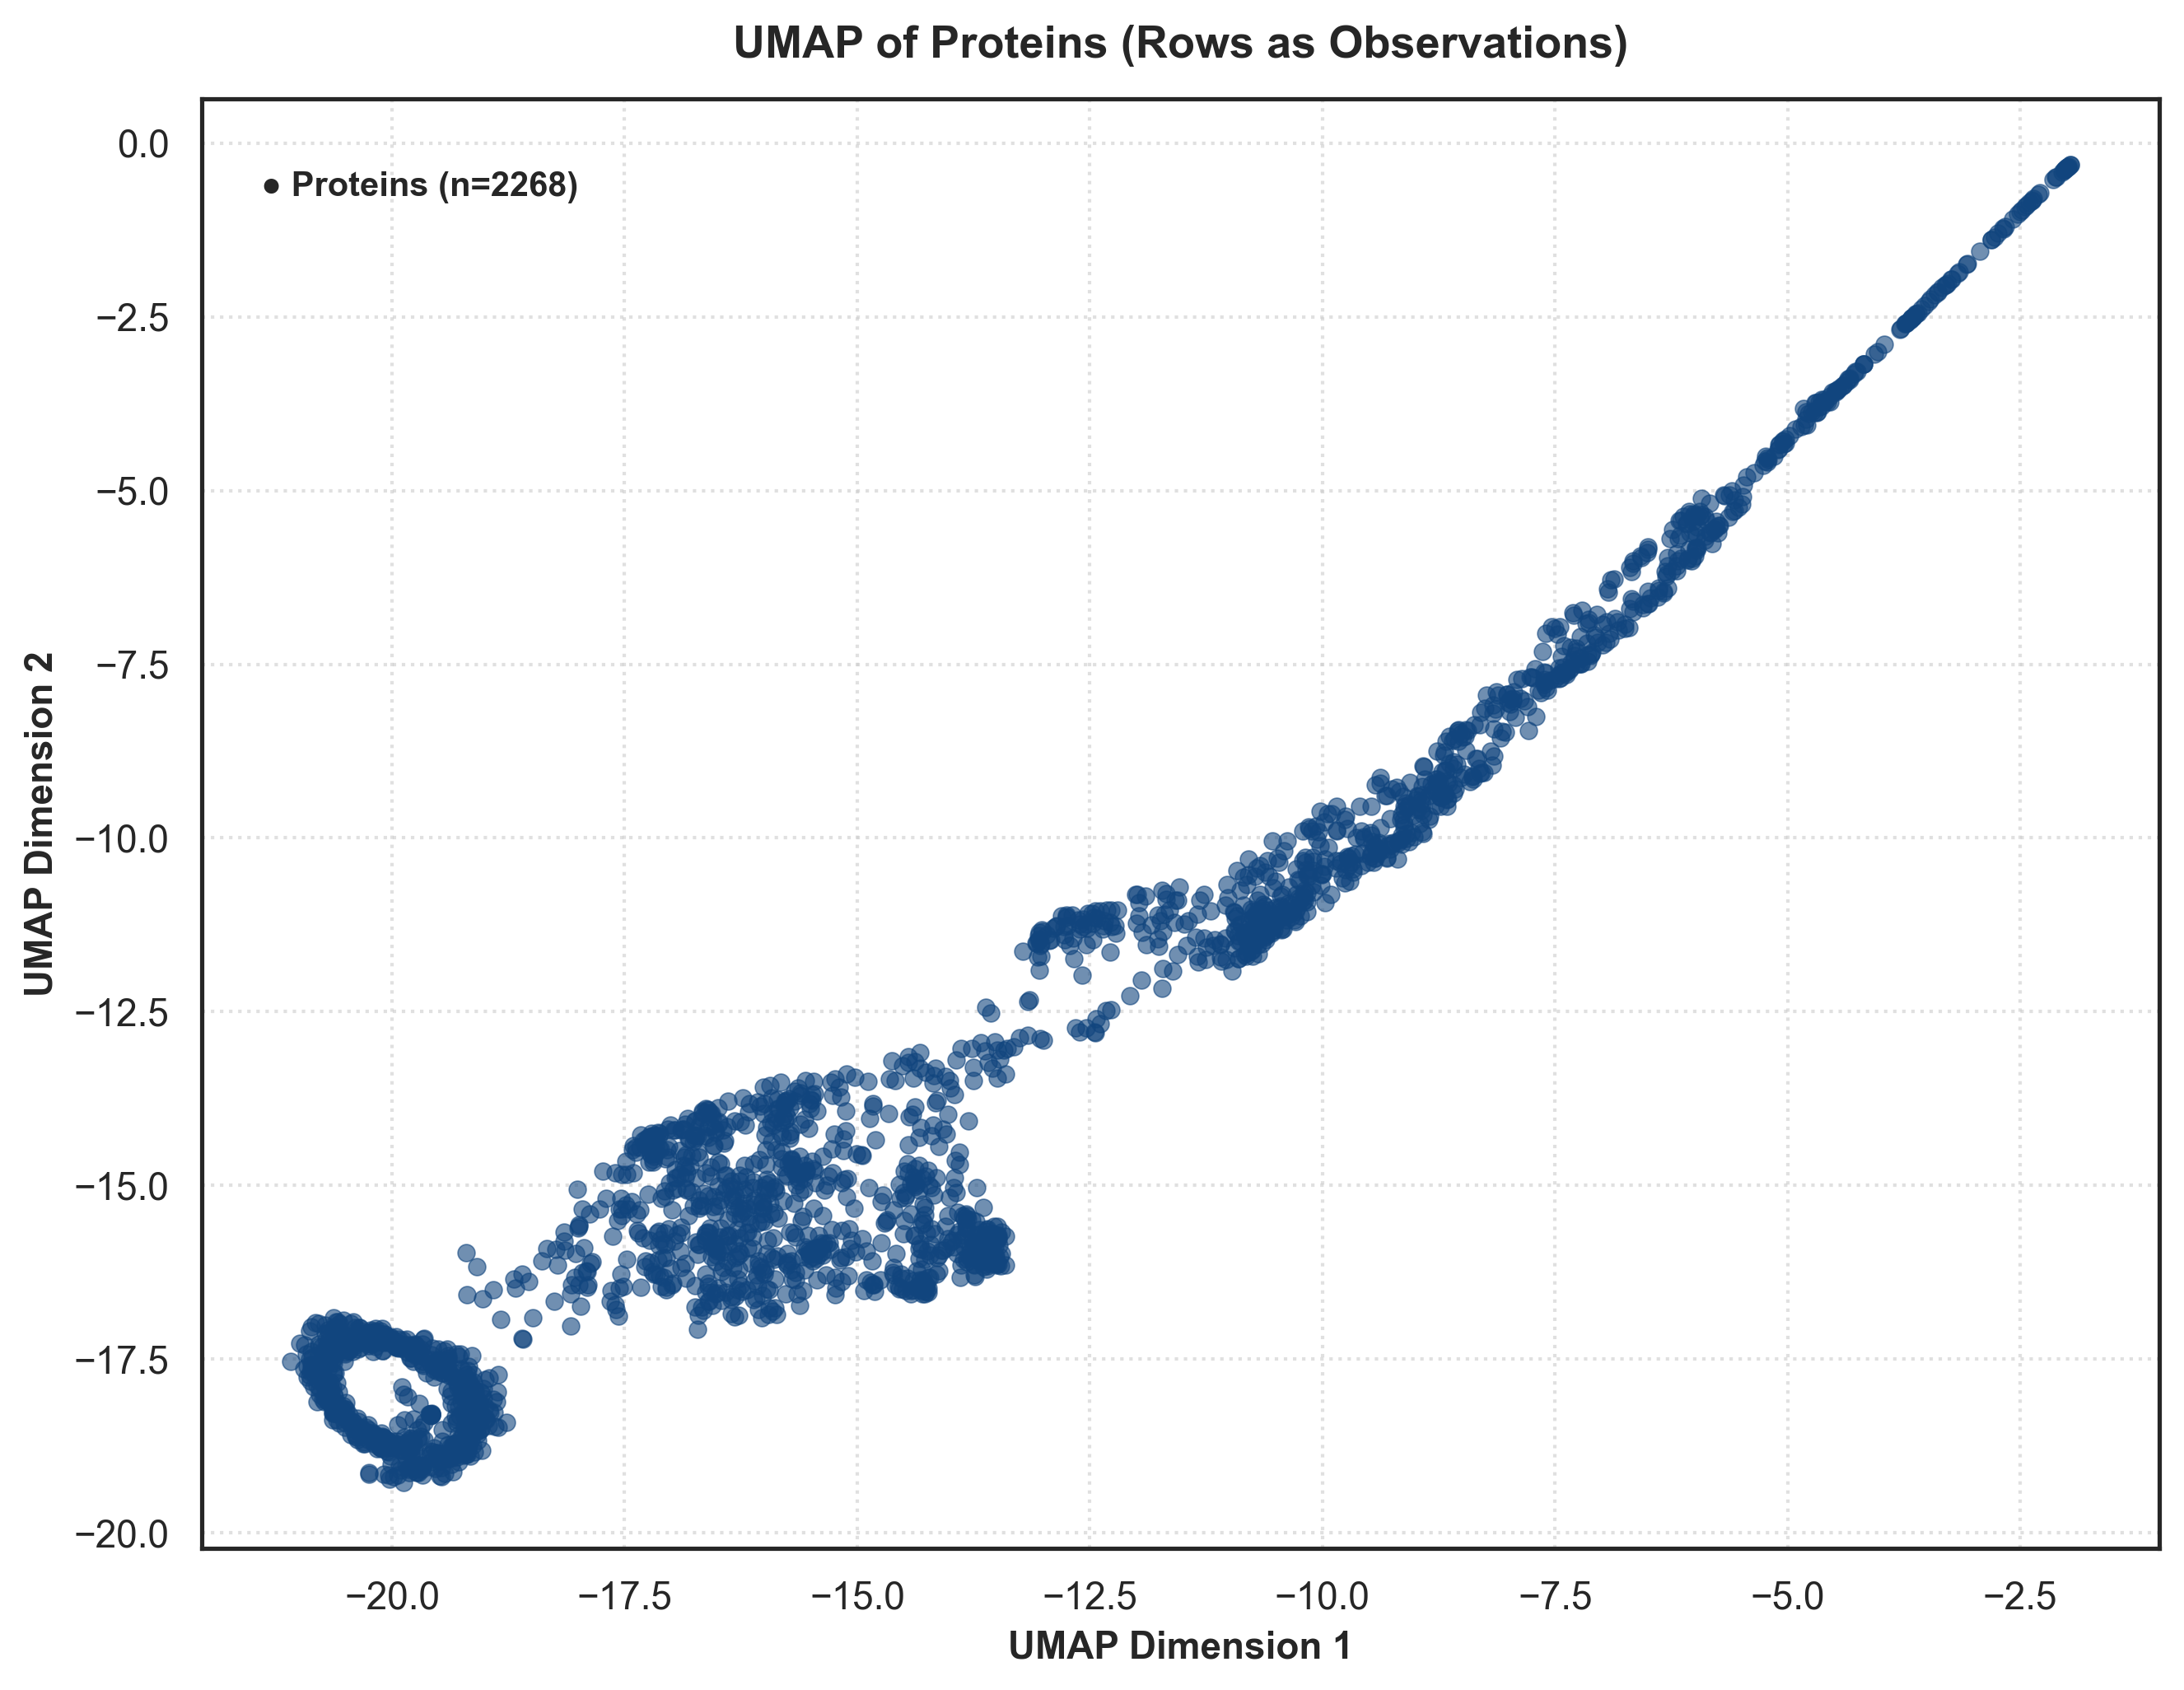

Running multi-class Logistic Regression across all conditions (5-Fold Out-of-Fold)...


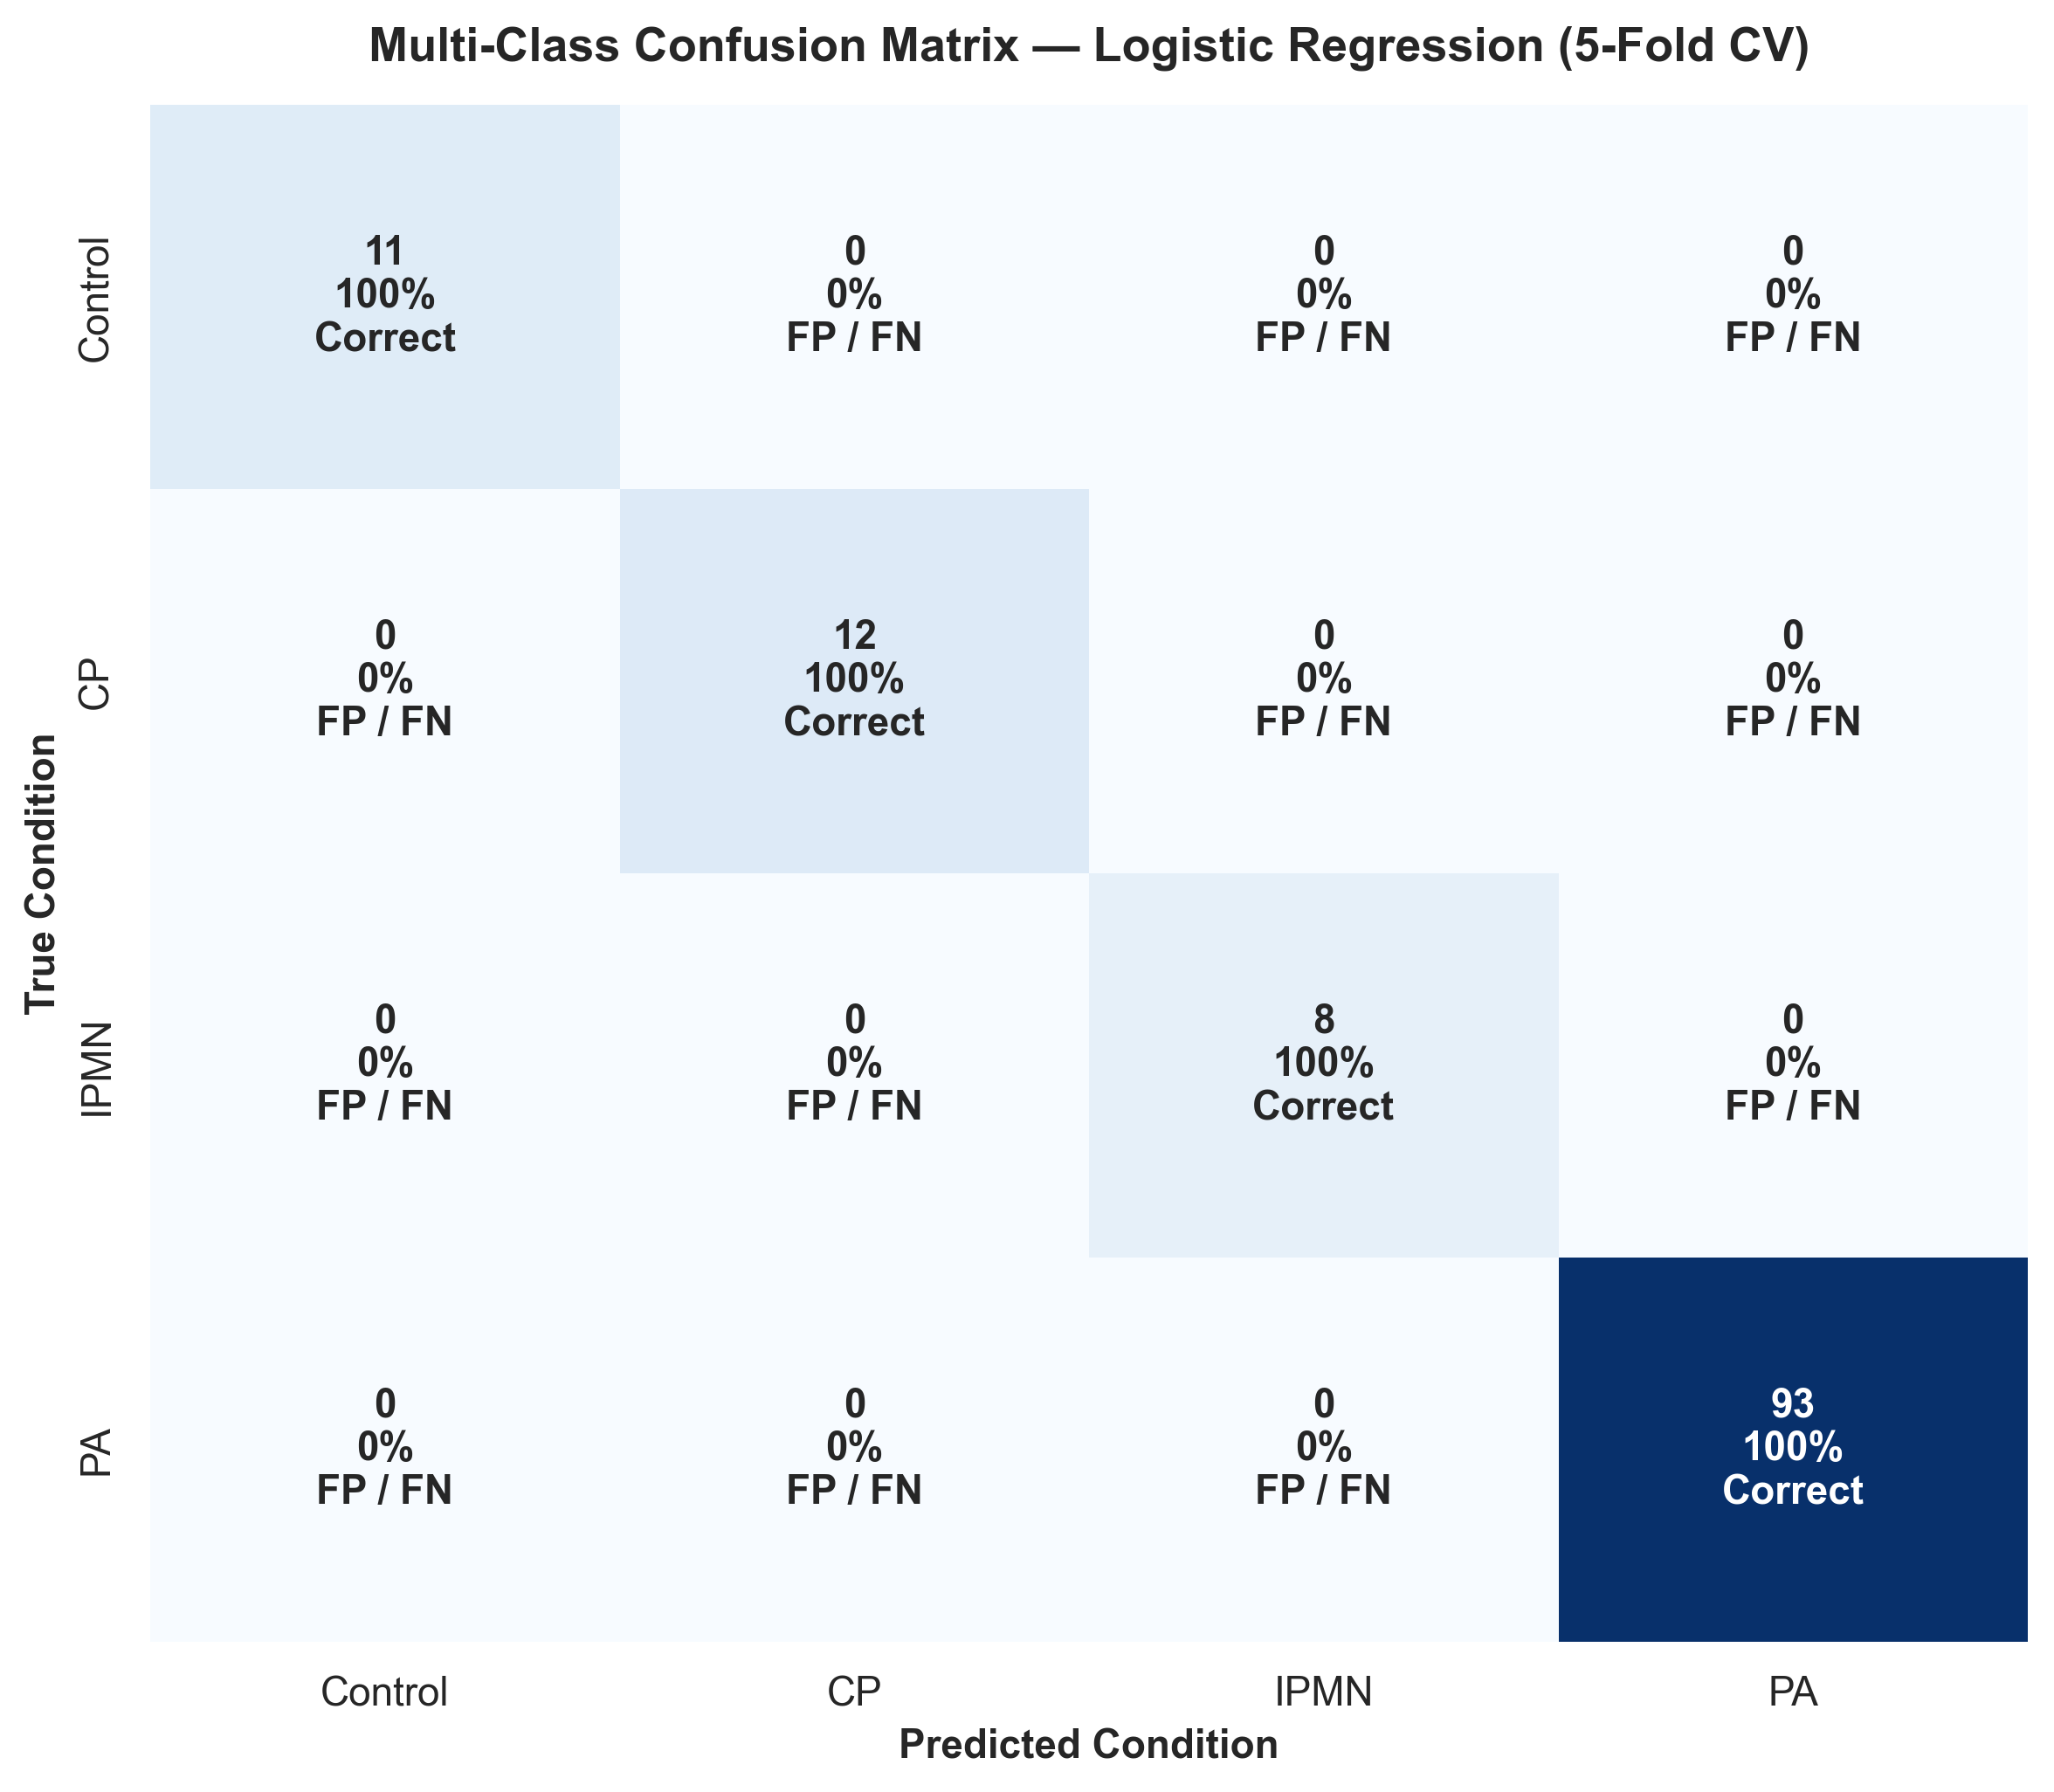


All analysis outputs successfully saved in 'benchmarks/'.


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import umap

def run_unscaled_proteomics_pipeline(file_path, output_dir="benchmarks"):
    os.makedirs(output_dir, exist_ok=True)
    
    print("Loading proteomics data...")
    xls = pd.ExcelFile(file_path)
    df = pd.read_excel(file_path, sheet_name=xls.sheet_names[0])
    
    abundance_cols = [c for c in df.columns if 'Abundances (Normalized):' in c]
    sample_to_group = {}
    for col in abundance_cols:
        text = col.split(':', 1)[1]
        tokens = [t.strip().upper() for t in text.split(',')]
        group_found = 'Other'
        for token in tokens:
            if 'CONTROL' in token:
                group_found = 'Control'
                break
            elif token == 'CP':
                group_found = 'CP'
                break
            elif 'IPMN' in token:
                group_found = 'IPMN'
                break
            elif token == 'PA':
                group_found = 'PA'
                break
        sample_to_group[col] = group_found

    groups = [sample_to_group[c] for c in abundance_cols]
    
    df[abundance_cols] = df[abundance_cols].fillna(0)
    
    name_col = 'Gene Symbol' if 'Gene Symbol' in df.columns else df.columns[0]
    df['temp_mean_abundance'] = df[abundance_cols].mean(axis=1)
    df = df.sort_values(by='temp_mean_abundance', ascending=False)
    df_filtered = df.drop_duplicates(subset=[name_col], keep='first').copy()
    df_filtered = df_filtered.drop(columns=['temp_mean_abundance'])

    log2_data = np.log2(df_filtered[abundance_cols].replace(0, np.nan))
    min_val = log2_data.min().min() if not log2_data.min().empty else 0
    log2_data = log2_data.fillna(min_val)

    row_mean = log2_data[abundance_cols].mean(axis=1)
    row_std = log2_data[abundance_cols].std(axis=1)
    z_row_wise = log2_data[abundance_cols].sub(row_mean, axis=0).div(row_std, axis=0).fillna(0)

    print("Generating Z-score distribution boxplot...")
    plt.figure(figsize=(18, 5), dpi=300)
    sns.set_theme(style="white")
    sns.boxplot(data=z_row_wise, palette="coolwarm", fliersize=1, linewidth=0.5)
    plt.title("Z-score Distribution Across Proteomics Samples", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("Samples", fontsize=10, fontweight='bold')
    plt.ylabel("Abundance (z-score)", fontsize=10, fontweight='bold')
    plt.xticks(rotation=90, fontsize=4)
    plt.yticks(fontsize=9)
    plt.grid(axis='y', linestyle=':', alpha=0.5)
    plt.tight_layout()
    box_path = os.path.join(output_dir, "zscore_distribution_proteomics.png")
    plt.savefig(box_path, dpi=300, bbox_inches='tight')
    plt.show()

    X_samples = log2_data[abundance_cols].T.values
    pca_samples = PCA(n_components=2)
    sample_pcs = pca_samples.fit_transform(X_samples)
    sample_var = pca_samples.explained_variance_ratio_ * 100
    
    sample_pca_df = pd.DataFrame(data=sample_pcs, columns=['PC1', 'PC2'])
    sample_pca_df['Sample'] = abundance_cols
    sample_pca_df['Group'] = groups

    palette_4g = {'Control': 'darkred', 'CP': 'darkblue', 'IPMN': 'forestgreen', 'PA': 'purple'}

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(
        data=sample_pca_df, x='PC1', y='PC2', hue='Group',
        palette=palette_4g, s=80, alpha=0.85, edgecolor='k', linewidth=0.5
    )
    plt.title("PCA — Principal Component Analysis", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel(f"PC1 ({sample_var[0]:.1f}% variance)", fontsize=11, fontweight='bold')
    plt.ylabel(f"PC2 ({sample_var[1]:.1f}% variance)", fontsize=11, fontweight='bold')
    
    group_counts = pd.Series(groups).value_counts()
    handles, labels = plt.gca().get_legend_handles_labels()
    new_labels = [f"{lbl} (n={group_counts.get(lbl, 0)})" for lbl in labels if lbl in group_counts]
    plt.legend(handles=handles[:len(new_labels)], labels=new_labels, title='Condition', loc='best', frameon=True, fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    pca_path = os.path.join(output_dir, "pca_samples.png")
    plt.savefig(pca_path, dpi=300, bbox_inches='tight')
    plt.show()

    print("Running Sample-level UMAP...")
    reducer_samples = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    sample_umap_emb = reducer_samples.fit_transform(X_samples)

    sample_umap_df = pd.DataFrame(data=sample_umap_emb, columns=['UMAP1', 'UMAP2'])
    sample_umap_df['Sample'] = abundance_cols
    sample_umap_df['Group'] = groups

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(
        data=sample_umap_df, x='UMAP1', y='UMAP2', hue='Group',
        palette=palette_4g, s=80, alpha=0.85, edgecolor='k', linewidth=0.5
    )
    plt.title("UMAP — Uniform Manifold Approximation (Samples)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("UMAP Dimension 1", fontsize=11, fontweight='bold')
    plt.ylabel("UMAP Dimension 2", fontsize=11, fontweight='bold')
    plt.legend(handles=handles[:len(new_labels)], labels=new_labels, title='Condition', loc='best', frameon=True, fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    umap_path = os.path.join(output_dir, "umap_samples.png")
    plt.savefig(umap_path, dpi=300, bbox_inches='tight')
    plt.show()

    print("Running Protein-level UMAP...")
    X_proteins = log2_data[abundance_cols].values.astype(float)
    reducer_proteins = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    protein_umap_emb = reducer_proteins.fit_transform(X_proteins)

    protein_umap_df = pd.DataFrame(data=protein_umap_emb, columns=['UMAP1', 'UMAP2'])
    protein_umap_df['Gene Symbol'] = df_filtered[name_col].values

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(
        data=protein_umap_df, x='UMAP1', y='UMAP2',
        color='#11457E', s=25, alpha=0.6, edgecolor=None
    )
    plt.title("UMAP of Proteins (Rows as Observations)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("UMAP Dimension 1", fontsize=11, fontweight='bold')
    plt.ylabel("UMAP Dimension 2", fontsize=11, fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.text(0.03, 0.95, f"● Proteins (n={len(df_filtered)})", transform=plt.gca().transAxes, fontsize=10, fontweight='bold', verticalalignment='top')
    plt.tight_layout()
    protein_umap_path = os.path.join(output_dir, "umap_proteins.png")
    plt.savefig(protein_umap_path, dpi=300, bbox_inches='tight')
    plt.show()


    y_multiclass = np.array(groups)
    unique_in_data = list(np.unique(y_multiclass))
    desired_order = ['Control', 'Cp', 'Ipmn', 'Pa']
    labels_order = []
    for d in desired_order:
        for u in unique_in_data:
            if u.lower() == d.lower() and u not in labels_order:
                labels_order.append(u)
    if len(labels_order) < len(unique_in_data):
        labels_order = unique_in_data

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_samples)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    oof_probs = np.zeros((len(y_multiclass), len(labels_order)))

    for train_idx, val_idx in cv.split(X_scaled, y_multiclass):
        X_tr, X_val = X_scaled[train_idx], X_scaled[val_idx]
        y_tr = y_multiclass[train_idx]
        
        for class_idx, target_class in enumerate(labels_order):
            y_tr_binary = (y_tr == target_class).astype(int)
            
            clf = LogisticRegression(
                solver='lbfgs',
                max_iter=2000,
                C=1.0,
                random_state=42
            )
            clf.fit(X_tr, y_tr_binary)
            oof_probs[val_idx, class_idx] = clf.predict_proba(X_val)[:, 1]
    y_pred_idx = np.argmax(oof_probs, axis=1)
    y_pred = np.array([labels_order[idx] for idx in y_pred_idx])
    cm = confusion_matrix(y_multiclass, y_pred, labels=labels_order)

    row_sums = cm.sum(axis=1, keepdims=True)
    annot_text = np.empty_like(cm, dtype=object)
    for r in range(len(labels_order)):
        for c in range(len(labels_order)):
            count = cm[r, c]
            pct = (count / row_sums[r, 0] * 100) if row_sums[r, 0] > 0 else 0
            tag = "Correct" if r == c else "FP / FN"
            annot_text[r, c] = f"{count}\n{pct:.0f}%\n{tag}"

    plt.figure(figsize=(8, 7), dpi=300)
    sns.heatmap(
        cm, 
        annot=annot_text, 
        fmt='', 
        cmap='Blues', 
        cbar=False,
        xticklabels=labels_order, 
        yticklabels=labels_order,
        annot_kws={"size": 11, "weight": "bold"}
    )

    plt.title("Multi-Class Confusion Matrix — Logistic Regression (5-Fold CV)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Predicted Condition", fontsize=11, fontweight='bold')
    plt.ylabel("True Condition", fontsize=11, fontweight='bold')
    plt.tight_layout()

    cm_path = os.path.join(output_dir, "multiclass_confusion_matrix_logreg.png")
    plt.savefig(cm_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\nAll analysis outputs successfully saved in '{output_dir}/'.")


if __name__ == "__main__":
    run_unscaled_proteomics_pipeline("data/pdac_ev_proteomics.xlsx")